<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Manejo_de_Dataset_Plataforma_Ultralytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q -U ultralytics nest_asyncio

In [ ]:
import nest_asyncio
nest_asyncio.apply()

In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
from google.colab import files
archivos = files.upload()  # selecciona el .ndjson
ndjson_path = next(iter(archivos))

Saving denpar-periapical.ndjson to denpar-periapical (1).ndjson


In [ ]:
modelo = YOLO("yolo26n.pt")

In [ ]:
# Si ya subiste el archivo a Colab:
ruta = "/content/denpar-periapical.ndjson"

with open(ruta, "r", encoding="utf-8") as f:
    for i, linea in enumerate(f):
        print(linea.rstrip())
        if i == 4:  # muestra las primeras 5 líneas
            break

{"type":"dataset","task":"segment","name":"DenPAR Periapical Radiographs","description":"DenPAR was released in 2025 by researchers at Sri Lanka's University of Peradeniya to support automated alveolar bone loss assessment. Its 1,000 intraoral periapical radiographs from the Dental Hospital Peradeniya outline every visible tooth, annotated by restorative dentistry specialists.","bytes":103592977,"url":"https://platform.ultralytics.com/ultralytics/datasets/denpar-periapical","class_names":{"0":"tooth"},"version":"latest","created_at":"2026-11-07T01:23:27.470Z","updated_at":"2026-11-07T01:23:40.846Z"}
{"type":"image","file":"270.jpg","url":"https://cdn.ul.run/eu/i/0028f3d5f25ef6a91ec572f41be0b8b6.jpg?Expires=1795089600&KeyName=key-v1&Signature=WeIrajJpNsXNM2n-VUTmneIRihY","width":1171,"height":886,"split":"test","annotations":{"segments":[[0,0.42188,0.02033,0.41076,0.0271,0.40563,0.03497,0.4022,0.04628,0.4022,0.06885,0.40394,0.07677,0.40394,0.11737,0.4065,0.11966,0.4005,0.13545,0.4005,0.

In [ ]:
import json

with open(ruta, "r", encoding="utf-8") as f:
    for i, linea in enumerate(f):
        objeto = json.loads(linea)
        print(json.dumps(objeto, indent=2, ensure_ascii=False))
        if i == 4:
            break

{
  "type": "dataset",
  "task": "segment",
  "name": "DenPAR Periapical Radiographs",
  "description": "DenPAR was released in 2025 by researchers at Sri Lanka's University of Peradeniya to support automated alveolar bone loss assessment. Its 1,000 intraoral periapical radiographs from the Dental Hospital Peradeniya outline every visible tooth, annotated by restorative dentistry specialists.",
  "bytes": 103592977,
  "url": "https://platform.ultralytics.com/ultralytics/datasets/denpar-periapical",
  "class_names": {
    "0": "tooth"
  },
  "version": "latest",
  "created_at": "2026-11-07T01:23:27.470Z",
  "updated_at": "2026-11-07T01:23:40.846Z"
}
{
  "type": "image",
  "file": "270.jpg",
  "url": "https://cdn.ul.run/eu/i/0028f3d5f25ef6a91ec572f41be0b8b6.jpg?Expires=1795089600&KeyName=key-v1&Signature=WeIrajJpNsXNM2n-VUTmneIRihY",
  "width": 1171,
  "height": 886,
  "split": "test",
  "annotations": {
    "segments": [
      [
        0,
        0.42188,
        0.02033,
        0.410

In [ ]:
with open(ruta, "r", encoding="utf-8") as f:
    print("Registros:", sum(1 for _ in f))

Registros: 987


In [ ]:
resultado = modelo.train(
    data=ndjson_path,
    epochs=10,
    imgsz=640
)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=denpar-periapical.ndjson, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

In [ ]:
import glob
from ultralytics import YOLO

# Cargar el mejor modelo guardado durante el entrenamiento anterior
modelo_best = YOLO("/content/runs/detect/train/weights/best.pt")

# Buscar el directorio donde se generó el dataset de prueba (test split)
# El transformador de ultralytics crea la estructura en /content/datasets/denpar-periapical-...
rutas_dataset = glob.glob("/content/datasets/denpar-periapical-*/images/val")

if rutas_dataset:
    test_dir = rutas_dataset[0]  # Usamos el set de validación/test extraído
    print(f"Corriendo predicciones en: {test_dir}")

    # Realizar la predicción guardando los resultados y filtrando solo por la clase 0 (tooth)
    resultados = modelo_best.predict(
        source=test_dir,
        classes=[0],  # Filtra solo clase 0
        save=True,
        imgsz=640
    )
    print("¡Prueba completada! Los resultados se han guardado en el directorio de 'runs/detect/predict'.")
else:
    print("No se encontró el directorio de imágenes de prueba automáticamente. Por favor, verifica la ruta de extracción del dataset.")

Corriendo predicciones en: /content/datasets/denpar-periapical-99f17de3/images/val

image 1/148 /content/datasets/denpar-periapical-99f17de3/images/val/03174c90b8f513a827d2ff6ca09a8b00_839.jpg: 512x640 4 tooths, 9.6ms
image 2/148 /content/datasets/denpar-periapical-99f17de3/images/val/03de2f6052196f83fdf2630dffc3f744_840.jpg: 640x576 5 tooths, 34.3ms
image 3/148 /content/datasets/denpar-periapical-99f17de3/images/val/062466d4b052ee373c3fdff19c6677b7_841.jpg: 512x640 5 tooths, 11.7ms
image 4/148 /content/datasets/denpar-periapical-99f17de3/images/val/0645cd6a267a91fe8c6ac99690857de6_842.jpg: 640x480 3 tooths, 28.7ms
image 5/148 /content/datasets/denpar-periapical-99f17de3/images/val/07e506350e966df16aa7f7037274abc8_843.jpg: 576x640 2 tooths, 27.3ms
image 6/148 /content/datasets/denpar-periapical-99f17de3/images/val/09917552035f5ee8b51f119d6ce226d9_844.jpg: 640x512 5 tooths, 26.4ms
image 7/148 /content/datasets/denpar-periapical-99f17de3/images/val/0a8113d55cbb4a3d8ff97bf570507ca2_845.jp

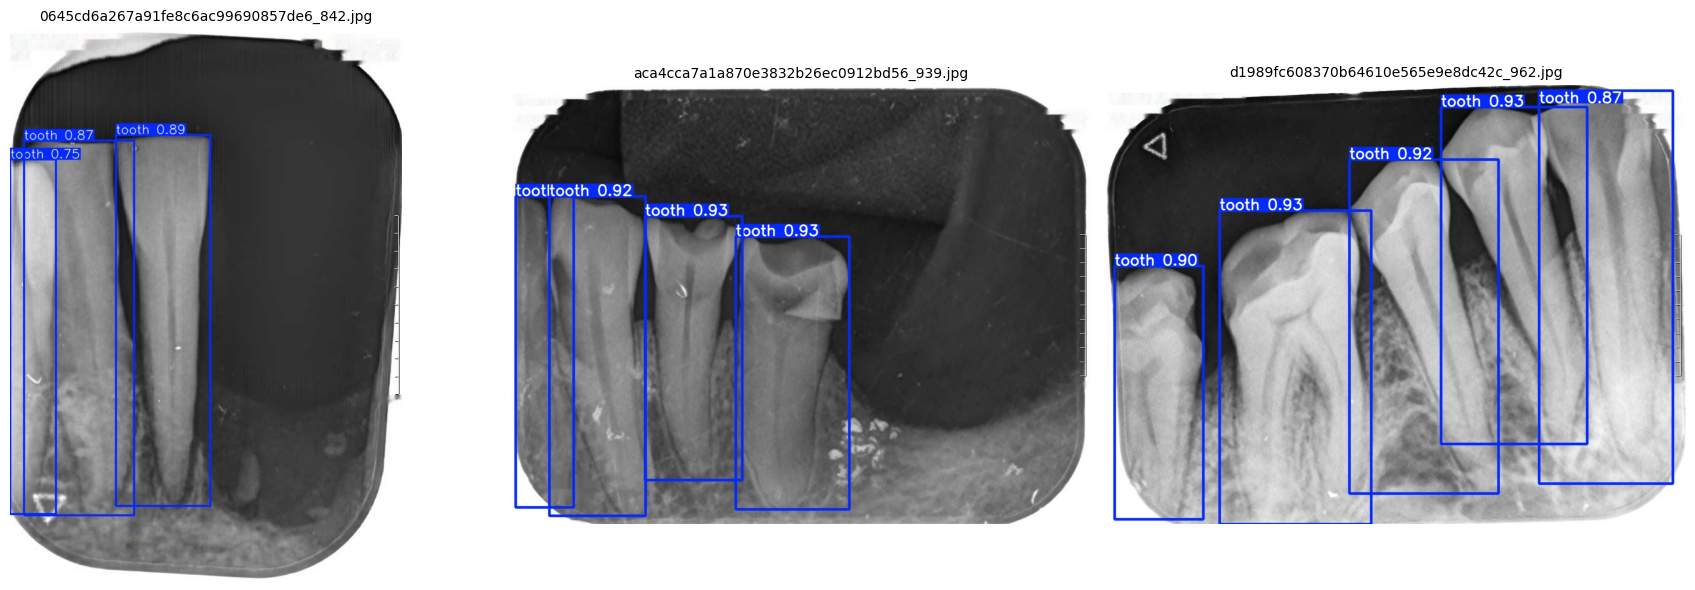

In [ ]:
import glob
import random
import matplotlib.pyplot as plt
import cv2

# Obtener la lista de imágenes resultantes en la carpeta de predicción
imagenes_predichas = glob.glob("/content/runs/detect/predict/*.jpg")

if imagenes_predichas:
    # Seleccionar 3 imágenes aleatorias para visualizar
    muestra = random.sample(imagenes_predichas, min(3, len(imagenes_predichas)))

    fig, axes = plt.subplots(1, len(muestra), figsize=(18, 6))
    if len(muestra) == 1:
      axes = [axes]

    for ax, ruta_img in zip(axes, muestra):
        img = cv2.imread(ruta_img)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img_rgb)
        ax.axis("off")
        ax.set_title(ruta_img.split("/")[-1], fontsize=10)

    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron imágenes en el directorio de predicción. Asegúrate de que las predicciones se guardaron correctamente.")

In [ ]:
from ultralytics import YOLO

# Cargamos un modelo preentrenado específico para segmentación (YOLO segment)
modelo_seg = YOLO("yolo26n-seg.pt")

# Entrenamos el modelo de segmentación con los mismos parámetros
resultados_seg = modelo_seg.train(
    data=ndjson_path,
    epochs=10,
    imgsz=640
)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=denpar-periapical.ndjson, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimiz

In [ ]:
import glob
from ultralytics import YOLO

# Cargar el mejor modelo guardado durante el entrenamiento anterior
modelo_best = YOLO("/content/runs/detect/train/weights/best.pt")

# Buscar el directorio donde se generó el dataset de prueba (test split)
# El transformador de ultralytics crea la estructura en /content/datasets/denpar-periapical-...
rutas_dataset = glob.glob("/content/datasets/denpar-periapical-*/images/val")

if rutas_dataset:
    test_dir = rutas_dataset[0]  # Usamos el set de validación/test extraído
    print(f"Corriendo predicciones en: {test_dir}")

    # Realizar la predicción guardando los resultados y filtrando solo por la clase 0 (tooth)
    resultados = modelo_best.predict(
        source=test_dir,
        classes=[0],  # Filtra solo clase 0
        save=True,
        imgsz=640
    )
    print("¡Prueba completada! Los resultados se han guardado en el directorio de 'runs/detect/predict'.")
else:
    print("No se encontró el directorio de imágenes de prueba automáticamente. Por favor, verifica la ruta de extracción del dataset.")

Corriendo predicciones en: /content/datasets/denpar-periapical-99f17de3/images/val

image 1/148 /content/datasets/denpar-periapical-99f17de3/images/val/03174c90b8f513a827d2ff6ca09a8b00_839.jpg: 512x640 4 tooths, 17.1ms
image 2/148 /content/datasets/denpar-periapical-99f17de3/images/val/03de2f6052196f83fdf2630dffc3f744_840.jpg: 640x576 5 tooths, 12.5ms
image 3/148 /content/datasets/denpar-periapical-99f17de3/images/val/062466d4b052ee373c3fdff19c6677b7_841.jpg: 512x640 5 tooths, 12.1ms
image 4/148 /content/datasets/denpar-periapical-99f17de3/images/val/0645cd6a267a91fe8c6ac99690857de6_842.jpg: 640x480 3 tooths, 13.8ms
image 5/148 /content/datasets/denpar-periapical-99f17de3/images/val/07e506350e966df16aa7f7037274abc8_843.jpg: 576x640 2 tooths, 11.1ms
image 6/148 /content/datasets/denpar-periapical-99f17de3/images/val/09917552035f5ee8b51f119d6ce226d9_844.jpg: 640x512 5 tooths, 12.1ms
image 7/148 /content/datasets/denpar-periapical-99f17de3/images/val/0a8113d55cbb4a3d8ff97bf570507ca2_845.j

In [ ]:
import glob

# Buscamos la ruta de validación generada para correr las pruebas
rutas_dataset = glob.glob("/content/datasets/denpar-periapical-*/images/val")

if rutas_dataset:
    test_dir = rutas_dataset[0]
    print(f"Corriendo predicciones de segmentación en: {test_dir}")

    # Realizamos la inferencia guardando los resultados de segmentación (máscaras)
    resultados_pred_seg = modelo_seg.predict(
        source=test_dir,
        classes=[0],
        save=True,          # Guarda imágenes con las máscaras superpuestas
        imgsz=640
    )
    print("¡Predicciones de segmentación completadas!")
else:
    print("No se encontró el directorio de imágenes.")

Corriendo predicciones de segmentación en: /content/datasets/denpar-periapical-99f17de3/images/val

image 1/148 /content/datasets/denpar-periapical-99f17de3/images/val/03174c90b8f513a827d2ff6ca09a8b00_839.jpg: 512x640 4 tooths, 11.6ms
image 2/148 /content/datasets/denpar-periapical-99f17de3/images/val/03de2f6052196f83fdf2630dffc3f744_840.jpg: 640x576 5 tooths, 16.8ms
image 3/148 /content/datasets/denpar-periapical-99f17de3/images/val/062466d4b052ee373c3fdff19c6677b7_841.jpg: 512x640 5 tooths, 13.8ms
image 4/148 /content/datasets/denpar-periapical-99f17de3/images/val/0645cd6a267a91fe8c6ac99690857de6_842.jpg: 640x480 3 tooths, 20.0ms
image 5/148 /content/datasets/denpar-periapical-99f17de3/images/val/07e506350e966df16aa7f7037274abc8_843.jpg: 576x640 2 tooths, 16.2ms
image 6/148 /content/datasets/denpar-periapical-99f17de3/images/val/09917552035f5ee8b51f119d6ce226d9_844.jpg: 640x512 5 tooths, 15.2ms
image 7/148 /content/datasets/denpar-periapical-99f17de3/images/val/0a8113d55cbb4a3d8ff97b

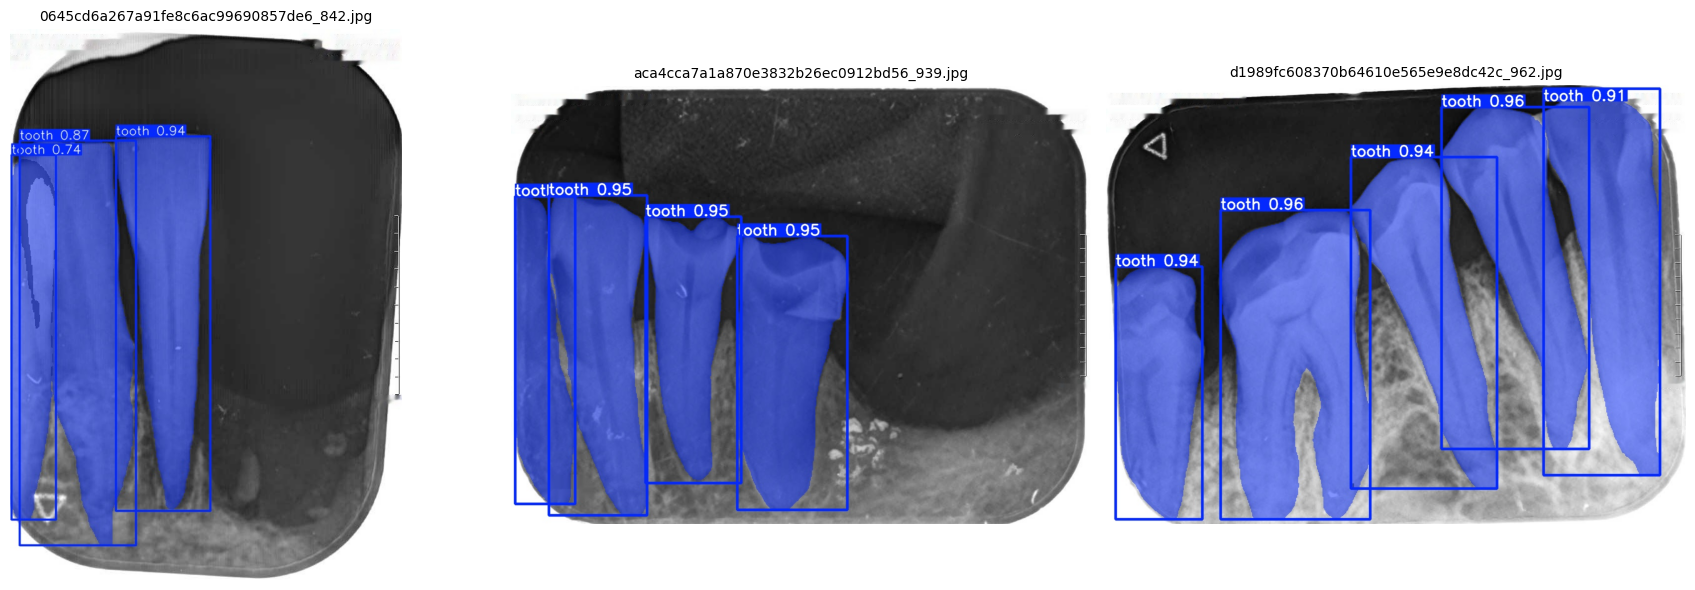

In [ ]:
import glob
import random
import matplotlib.pyplot as plt
import cv2

# Obtener las imágenes de la última carpeta de predicción generada (segmentación)
carpetas_predict = sorted(glob.glob("/content/runs/segment/predict*"))
if carpetas_predict:
    ultima_carpeta = carpetas_predict[-1]
    imagenes_seg = glob.glob(f"{ultima_carpeta}/*.jpg")

    if imagenes_seg:
        muestra_seg = random.sample(imagenes_seg, min(3, len(imagenes_seg)))

        fig, axes = plt.subplots(1, len(muestra_seg), figsize=(18, 6))
        if len(muestra_seg) == 1:
            axes = [axes]

        for ax, ruta_img in zip(axes, muestra_seg):
            img = cv2.imread(ruta_img)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb)
            ax.axis("off")
            ax.set_title(ruta_img.split("/")[-1], fontsize=10)

        plt.tight_layout()
        plt.show()
    else:
        print("No se encontraron imágenes segmentadas en la carpeta de resultados.")
else:
    print("No se ha encontrado ninguna carpeta de predicciones de segmentación.")